# 05 — Out-of-sample checks

1. **Prepayment, rolling origin.** For each of the last six payoff months, refit using earlier months only,
   then forecast every pool. The benchmarks are a single pooled S-curve and each pool's trailing six-month
   speed. The score is binomial deviance (lower is better).
2. **Rate sensitivity.** Weekly regression of $\Delta\ln P$ (clean mid) on $\Delta$10Y with Newey–West
   errors. $-\beta$ is an empirical duration. It includes any co-movement of spreads with rates, so it is
   context for the model duration, not a direct test.
3. **Month-ahead factor.** A pre-registered forecast of the next published factor, scored by
   `validation.score_month_ahead` once it is released.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps

ps.apply()
pd.set_option("display.width", 140)
CUSIP = "3140QVLM4"

In [2]:
import json
from run_security_analytics import estimate_prepayment, load_inputs
from validation import empirical_duration, rolling_origin_prepay_test

inputs = load_inputs(CUSIP)
est = estimate_prepayment(inputs, n_boot=20, seed=42)
order = [row["cusip"] for row in inputs["config"]["securities"]]
labels = {row["cusip"]: f"{row['coupon'] * 100:.1f}% pool" for row in inputs["config"]["securities"]}
oos = rolling_origin_prepay_test(est["panel"], list(est["fit"].floors), est["fit"].ceiling)
pd.DataFrame({k: v for k, v in oos["summary"].items() if isinstance(v, dict)}).T.assign(
    mae_cpr=lambda d: d["mae_cpr"] * 100, bias_cpr=lambda d: d["bias_cpr"] * 100).round(2)

,deviance,mae_cpr,bias_cpr
model,18.08,5.70,-0.01
pooled,15.06,5.73,-1.56
naive,24.01,7.41,1.84


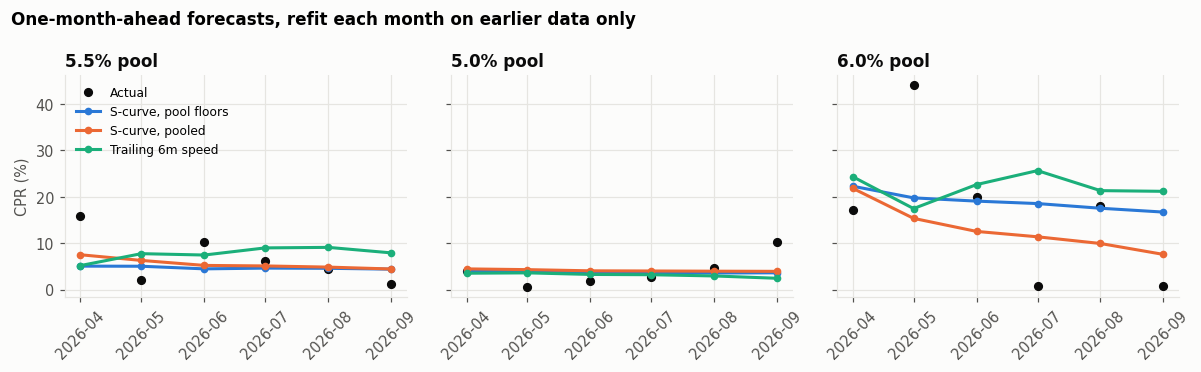

In [3]:
table = oos["table"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, cusip in zip(axes, order):
    sub = table.loc[table["cusip"] == cusip].sort_values("activity_month")
    ax.plot(sub["activity_month"], sub["cpr_actual"] * 100, color=ps.INK, marker="o", linewidth=0, label="Actual")
    ax.plot(sub["activity_month"], sub["cpr_model"] * 100, color=ps.SERIES[0], marker="o", markersize=4, label="S-curve, pool floors")
    ax.plot(sub["activity_month"], sub["cpr_pooled"] * 100, color=ps.SERIES[1], marker="o", markersize=4, label="S-curve, pooled")
    ax.plot(sub["activity_month"], sub["cpr_naive"] * 100, color=ps.SERIES[2], marker="o", markersize=4, label="Trailing 6m speed")
    ax.set_title(labels[cusip])
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("CPR (%)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("One-month-ahead forecasts, refit each month on earlier data only", x=0.01, ha="left",
             fontsize=11, fontweight="semibold")
fig.tight_layout()
_ = ps.save(fig, "05_prepay_out_of_sample")

In [4]:
report_path = ROOT / "artifacts" / "results" / f"{CUSIP}_{inputs['trade_date'].date()}_valuation.json"
report = json.loads(report_path.read_text())
emp = empirical_duration(inputs["market_history"], inputs["cmt"], inputs["trade_date"])
rows = {}
for window, res in emp.items():
    for factor in ("y10", "level"):
        rows[f"{window} vs {factor}"] = {"weeks": res["n_weeks"], "duration": res[factor]["duration"],
                                         "se": res[factor]["se"], "CI low": res[factor]["ci95"][0],
                                         "CI high": res[factor]["ci95"][1], "R2": res[factor]["r2"]}
print(f"model effective duration {report['valuation']['eff_duration']:.2f} "
      f"(MC se {report['valuation']['eff_duration_se']:.3f}; parameter 95% CI "
      f"{report['parameter_uncertainty']['eff_duration']['ci95'][0]:.2f}–{report['parameter_uncertainty']['eff_duration']['ci95'][1]:.2f})")
pd.DataFrame(rows).T.round(2)

model effective duration 6.07 (MC se 0.031; parameter 95% CI 5.55–7.10)


,weeks,duration,se,CI low,CI high,R2
last_26w vs y10,26.0,5.27,0.62,4.06,6.47,0.84
last_26w vs level,26.0,5.39,0.65,4.12,6.66,0.83
last_52w vs y10,52.0,4.23,0.74,2.77,5.68,0.70
last_52w vs level,52.0,4.38,0.73,2.96,5.81,0.70
full vs y10,106.0,4.12,0.29,3.56,4.68,0.81
full vs level,106.0,4.33,0.28,3.78,4.89,0.81


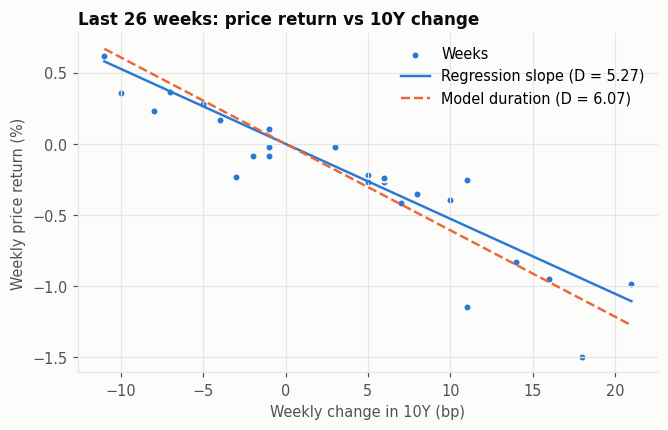

In [5]:
prices = inputs["market_history"].set_index("date")["price"]
common = prices.index.intersection(inputs["cmt"].index)
weekly = pd.DataFrame({"lp": np.log(prices.loc[common]), "y10": inputs["cmt"].loc[common, 10.0]}).resample("W-FRI").last()
chg = weekly.diff().dropna().tail(26)
dur_emp = emp["last_26w"]["y10"]["duration"]
dur_model = report["valuation"]["eff_duration"]
xs = np.linspace(chg["y10"].min(), chg["y10"].max(), 50)
fig, ax = plt.subplots(figsize=(6.8, 4))
ax.scatter(chg["y10"] * 1e4, chg["lp"] * 100, color=ps.SERIES[0], s=26, edgecolor=ps.SURFACE, linewidth=1.2, label="Weeks")
ax.plot(xs * 1e4, -dur_emp * xs * 100, color=ps.SERIES[0], linewidth=1.6, label=f"Regression slope (D = {dur_emp:.2f})")
ax.plot(xs * 1e4, -dur_model * xs * 100, color=ps.SERIES[1], linestyle="--", linewidth=1.6, label=f"Model duration (D = {dur_model:.2f})")
ax.set(xlabel="Weekly change in 10Y (bp)", ylabel="Weekly price return (%)", title="Last 26 weeks: price return vs 10Y change")
ax.legend(loc="upper right")
_ = ps.save(fig, "05_empirical_duration")

In [6]:
fc = report["month_ahead_forecast"]
print(f"Forecast of the {fc['factor_month']} factor (payoffs in {fc['payoff_month']}, published {fc['publication_date']}):")
print(f"  driving PMMS {fc['driving_mortgage_rate'] * 100:.3f}% -> incentive {fc['incentive'] * 1e4:+.0f} bp, "
      f"point CPR {fc['point_cpr'] * 100:.2f}%")
print(f"  factor point {fc['point_factor']:.6f}; 90% interval {fc['factor_pi90'][0]:.6f} to {fc['factor_pi90'][1]:.6f}")
print(f"  probability of no full payoff in the month: {fc['prob_zero_full_payoffs']:.0%}")
print("Score when published:  from validation import score_month_ahead; score_month_ahead(fc, realized_factor)")

Forecast of the 2026-11 factor (payoffs in 2026-10, published 2026-11-05):
  driving PMMS 6.862% -> incentive -32 bp, point CPR 4.07%
  factor point 0.871931; 90% interval 0.867884 to 0.874959
  probability of no full payoff in the month: 28%
Score when published:  from validation import score_month_ahead; score_month_ahead(fc, realized_factor)
